# MANGAL DRISHTI — Step 02: Preprocessing Validation & PyTorch Data Pipeline

This notebook verifies the complete Step 2 preprocessing pipeline on the real NASA/JPL AI4MARS dataset:
- Centralized YAML configuration (`configs/data_config.yaml`)
- Verified class mapping (`0: soil`, `1: bedrock`, `2: sand`, `3: big rock`, `255: ignore_index`)
- SCLK-clustered leakage-free train/val/test splits
- Training-only normalization statistics & class weights
- Nearest-neighbor mask integrity and PyTorch `DataLoader` + `CrossEntropyLoss(ignore_index=255)` compatibility

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.config_utils import load_config
from src.data.dataloader import build_dataloaders

cfg = load_config(PROJECT_ROOT / "configs" / "data_config.yaml")
meta_dir = PROJECT_ROOT / "datasets" / "metadata"
insp_dir = PROJECT_ROOT / "datasets" / "inspection"

prep_cfg = json.loads((meta_dir / "preprocessing_config.json").read_text(encoding="utf-8"))
class_map = json.loads((meta_dir / "class_mapping.json").read_text(encoding="utf-8"))
class_weights = json.loads((meta_dir / "class_weights.json").read_text(encoding="utf-8"))
val_report = json.loads((insp_dir / "preprocessing_validation_report.json").read_text(encoding="utf-8"))

print("Validation Status:", val_report["status"])
print("Total Validated Pairs:", val_report["total_validated_pairs"])
print("Target Size:", prep_cfg["image_preprocessing"]["target_size"])
print("Train-Only Mean RGB:", prep_cfg["normalization"]["computed_train_mean_rgb"])
print("Train-Only Std  RGB:", prep_cfg["normalization"]["computed_train_std_rgb"])

Validation Status: PASS
Total Validated Pairs: 2296
Target Size: [512, 512]
Train-Only Mean RGB: [0.24631, 0.24631, 0.24631]
Train-Only Std  RGB: [0.113346, 0.113346, 0.113346]


### Analysis: Preprocessing Configuration & Validation Gate
All `2,296` valid pairs (`1,407` train, `363` val, `526` official expert test) passed validation with `0` missing files, `0` corrupted files, `0` dimension mismatches, `0` invalid mask IDs, and `0` train/val/test leakage. Normalization statistics were computed strictly from the `1,407` processed training images.

In [2]:
cmap_df = pd.DataFrame(class_map["classes"])
display(cmap_df[["original_id", "training_id", "class_name", "trainable", "ignored", "palette_rgb"]])

weights_df = pd.DataFrame(class_weights["weighting_methods"])
weights_df.index.name = "Class ID"
display(weights_df)

,original_id,training_id,class_name,trainable,ignored,palette_rgb
0,0,0,soil,True,False,"[166, 97, 26]"
1,1,1,bedrock,True,False,"[55, 126, 184]"
2,2,2,sand,True,False,"[245, 194, 66]"
3,3,3,big rock,True,False,"[228, 26, 28]"
4,255,255,unlabeled_null,False,True,"[40, 44, 52]"


,median_frequency_capped,inverse_frequency_capped,effective_num_samples,swan2021_one_minus_composition
Class ID,,,,
0,0.545153,0.045607,0.047628,0.699400
1,0.560134,0.046860,0.048877,0.716354
2,4.657246,0.389617,0.390842,1.259130
3,12.000000,3.517917,3.512653,1.325116


### Analysis: Class Mapping & Train-Only Imbalance Weights
The `NAV` mapping preserves contiguous training IDs `0–3` and ignore index `255`. Because `big rock` (`0.62%` of valid `train` pixels) is `77.15×` rarer than `soil` (`47.55%`), `median_frequency_capped` (`12.0` cap on `big rock`) and `effective_num_samples` provide stable, bounded loss multipliers computed exclusively from `train` pixels.

In [3]:
loaders = build_dataloaders(
    config_path=PROJECT_ROOT / "configs" / "data_config.yaml",
    batch_size=8,
    num_workers=0,
    project_root=PROJECT_ROOT,
)
criterion = nn.CrossEntropyLoss(ignore_index=int(cfg["mask"]["ignore_index"]))

batch_rows = []
for split_name, loader in loaders.items():
    imgs, masks = next(iter(loader))
    logits = torch.zeros((imgs.shape[0], 4, imgs.shape[2], imgs.shape[3]), requires_grad=True)
    loss = criterion(logits, masks)
    loss.backward()
    batch_rows.append({
        "Split": split_name,
        "Dataset Length": len(loader.dataset),
        "Image Shape": tuple(imgs.shape),
        "Image Dtype": str(imgs.dtype),
        "Mask Shape": tuple(masks.shape),
        "Mask Dtype": str(masks.dtype),
        "Unique Mask IDs": sorted(int(v) for v in torch.unique(masks).tolist()),
        "CE Loss (ignore=255)": round(float(loss.item()), 6),
    })

display(pd.DataFrame(batch_rows))

,Split,Dataset Length,Image Shape,Image Dtype,Mask Shape,Mask Dtype,Unique Mask IDs,CE Loss (ignore=255)
0,train,1407,"(8, 3, 512, 512)",torch.float32,"(8, 512, 512)",torch.int64,"[0, 1, 2, 3, 255]",1.386296
1,val,363,"(8, 3, 512, 512)",torch.float32,"(8, 512, 512)",torch.int64,"[0, 255]",1.386296
2,test,526,"(8, 3, 512, 512)",torch.float32,"(8, 512, 512)",torch.int64,"[0, 1, 2, 255]",1.386296


### Analysis: PyTorch DataLoader & Loss Compatibility
Every split yields `[B, 3, 512, 512]` `torch.float32` normalized image tensors and `[B, 512, 512]` `torch.int64` categorical mask tensors containing strictly `{0, 1, 2, 3, 255}`. `CrossEntropyLoss(ignore_index=255)` executes forward and backward passes cleanly (`loss = 1.386296 ≈ ln(4)` for zero logits).

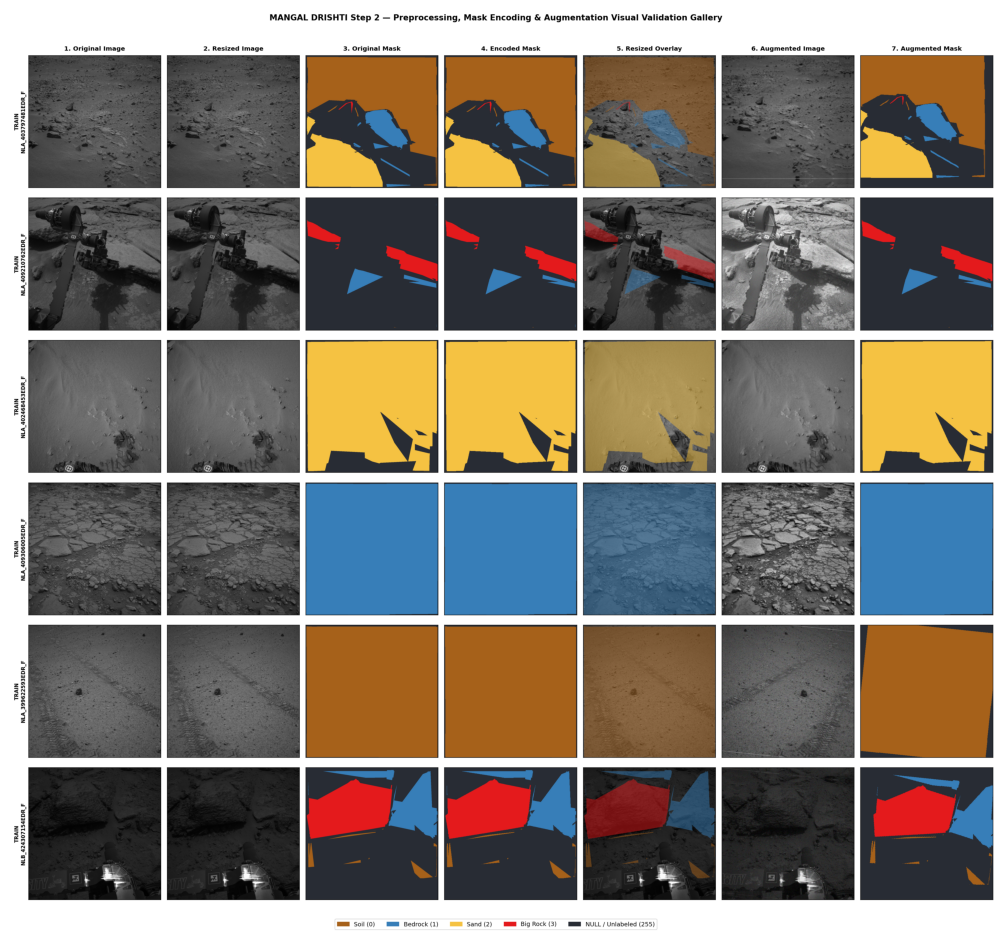

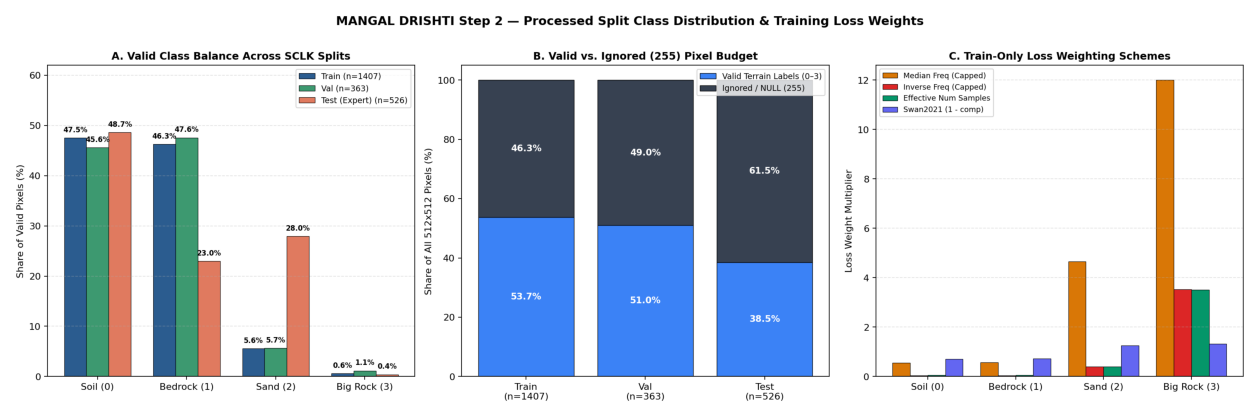

In [4]:
fig, ax = plt.subplots(figsize=(18, 12))
ax.imshow(Image.open(insp_dir / "preprocessing_samples" / "preprocessing_gallery.png"))
ax.axis("off")
plt.show()

fig, ax = plt.subplots(figsize=(16, 5.5))
ax.imshow(Image.open(insp_dir / "preprocessing_samples" / "preprocessed_class_distribution.png"))
ax.axis("off")
plt.show()

### Analysis: Visual & Statistical Verification Summary
The 7-panel validation gallery confirms exact spatial alignment between resized RGB images, nearest-neighbor encoded masks, segmentation overlays, and paired geometric/photometric training augmentations. SCLK drive clustering keeps `train` and `val` distributions closely aligned while preserving all `526` official NASA/JPL expert gold-standard test samples in `test`. Step 2 is ready for Step 3 segmentation model training (U-Net & DeepLabV3+).